# Attack Angle Model — MLB Statcast
Predicts `attack_angle` (vertical bat path angle at contact, degrees).  
Negative = downward swing, Positive = upward swing.

**Workflow**
1. Pull Statcast data (loads from `statcast_2024.parquet` cache if available)
2. Explore target distribution
3. Engineer features
4. Train XGBoost
5. Evaluate & inspect feature importance
6. Reliability (Cronbach's α) & stickiness (YoY Spearman ρ)
7. Save artifacts


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from pathlib import Path
from scipy import stats
from scipy.stats import spearmanr

from pybaseball import statcast
from xgboost import XGBRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.3f}".format)

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

print("Imports OK")


Imports OK


## 1. Pull Statcast Data
Loads from `statcast_2024.parquet` cache if available, otherwise pulls from Baseball Savant.

In [2]:
CACHE_PATH = Path("statcast_2024.parquet")

if CACHE_PATH.exists():
    print("Loading from cache …")
    raw = pd.read_parquet(CACHE_PATH)
else:
    print("Pulling from Baseball Savant (this takes ~5 minutes) …")
    chunks = []
    date_ranges = [
        ("2024-03-20", "2024-04-30"),
        ("2024-05-01", "2024-05-31"),
        ("2024-06-01", "2024-06-30"),
        ("2024-07-01", "2024-07-31"),
        ("2024-08-01", "2024-08-31"),
        ("2024-09-01", "2024-09-29"),
    ]
    for start, end in date_ranges:
        print(f"  {start} → {end}")
        chunk = statcast(start, end, verbose=False)
        chunks.append(chunk)
    raw = pd.concat(chunks, ignore_index=True)
    raw.to_parquet(CACHE_PATH)
    print(f"Cached to {CACHE_PATH}")

print(f"Shape: {raw.shape}")
print(f"attack_angle present: {'attack_angle' in raw.columns}")
print(f"attack_angle non-null: {raw['attack_angle'].notna().sum():,}  ({raw['attack_angle'].notna().mean()*100:.1f}%)")


Loading from cache …
Shape: (731904, 118)
attack_angle present: True
attack_angle non-null: 316,387  (43.2%)


## 2. Explore the Target Variable

In [3]:
TARGET = "attack_angle"

swing_mask = (
    raw[TARGET].notna() &
    raw["bat_speed"].notna() &
    raw["swing_length"].notna() &
    raw["launch_speed"].notna() &
    raw["hc_x"].notna() &
    raw["stand"].notna() &
    raw["pitch_type"].notna()
)
df_swings = raw[swing_mask].copy()
print(f"Swings with full tracking: {len(df_swings):,}")
print(f"\n{TARGET} distribution:")
print(df_swings[TARGET].describe().round(2))


Swings with full tracking: 113,337

attack_angle distribution:
count   113337.000
mean         8.440
std          9.380
min        -86.770
25%          3.240
50%          9.070
75%         14.410
max         86.090
Name: attack_angle, dtype: Float64


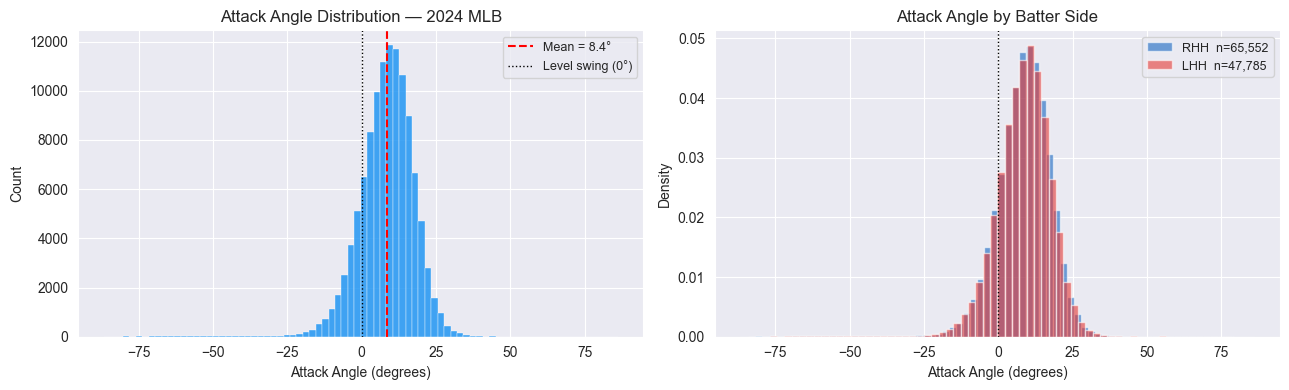

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

aa = df_swings[TARGET]

axes[0].hist(aa, bins=80, color="#2196F3", alpha=0.85, edgecolor="white", linewidth=0.3)
axes[0].axvline(aa.mean(), color="red", linewidth=1.5, linestyle="--", label=f"Mean = {aa.mean():.1f}°")
axes[0].axvline(0, color="black", linewidth=1, linestyle=":", label="Level swing (0°)")
axes[0].set_xlabel("Attack Angle (degrees)")
axes[0].set_ylabel("Count")
axes[0].set_title("Attack Angle Distribution — 2024 MLB")
axes[0].legend(fontsize=9)

for side, color, label in [("R", "#1565C0", "RHH"), ("L", "#E53935", "LHH")]:
    sub = df_swings[df_swings["stand"] == side][TARGET]
    axes[1].hist(sub, bins=70, alpha=0.6, color=color, label=f"{label}  n={len(sub):,}", density=True)
axes[1].axvline(0, color="black", linewidth=1, linestyle=":")
axes[1].set_xlabel("Attack Angle (degrees)")
axes[1].set_ylabel("Density")
axes[1].set_title("Attack Angle by Batter Side")
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()


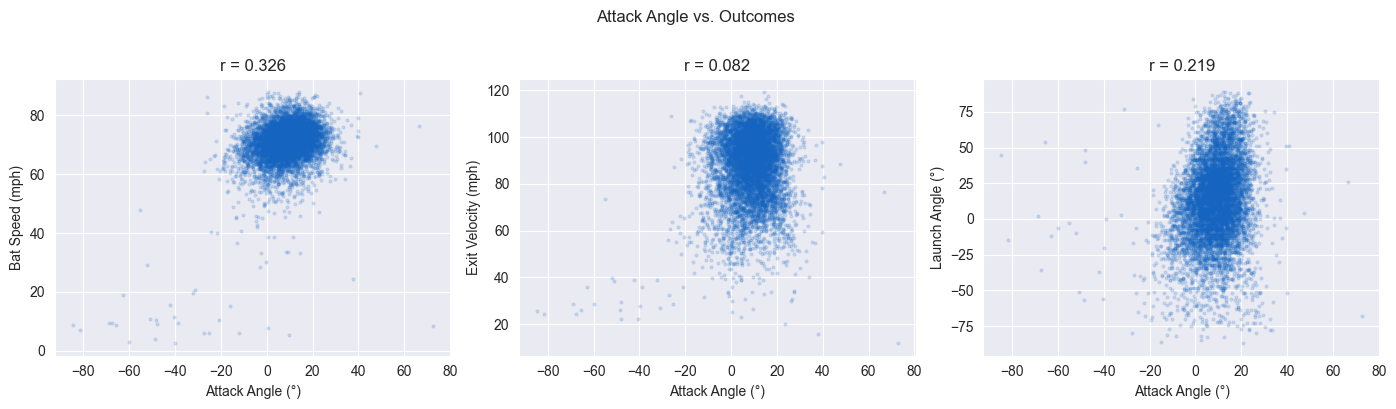

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

pairs = [
    ("bat_speed",    "Bat Speed (mph)"),
    ("launch_speed", "Exit Velocity (mph)"),
    ("launch_angle", "Launch Angle (°)"),
]
for ax, (col, label) in zip(axes, pairs):
    sample = df_swings.sample(min(8000, len(df_swings)), random_state=42)
    ax.scatter(sample[TARGET], sample[col], alpha=0.15, s=4, color="#1565C0")
    r = sample[[TARGET, col]].corr().iloc[0, 1]
    ax.set_xlabel("Attack Angle (°)")
    ax.set_ylabel(label)
    ax.set_title(f"r = {r:.3f}")

plt.suptitle("Attack Angle vs. Outcomes", y=1.01, fontsize=12)
plt.tight_layout()
plt.show()


## 3. Feature Engineering

In [102]:
PITCH_TYPE_MAP = {
    "FF": 0, "FA": 0,
    "SI": 1, "FT": 1,
    "FC": 2,
    "SL": 3, "ST": 3, "SV": 3,
    "CH": 4, "FS": 4, "FO": 4,
    "CU": 5, "KC": 5, "CS": 5,
    "KN": 6,
    "EP": 7,
}
STAND_MAP    = {"R": 0, "L": 1}
P_THROWS_MAP = {"R": 0, "L": 1}

def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # ── Location relative to batter (pull-side always positive)
    df["plate_x_rel"] = np.where(df["stand"] == "R", df["plate_x"], -df["plate_x"])

    # ── Vertical location relative to strike zone midpoint
    df["sz_mid"]      = (df["sz_top"] + df["sz_bot"]) / 2
    df["plate_z_rel"] = df["plate_z"] - df["sz_mid"]

    # ── Count flags
    df["is_2_strikes"]    = (df["strikes"] == 2).astype(int)
    df["is_hitter_count"] = (
        ((df["balls"] == 2) & (df["strikes"] == 0)) |
        ((df["balls"] == 3) & (df["strikes"] <= 1))
    ).astype(int)

    # ── Categorical encodings
    df["pitch_type_enc"] = df["pitch_type"].map(PITCH_TYPE_MAP).fillna(9).astype(int)
    df["stand_enc"]      = df["stand"].map(STAND_MAP).fillna(0).astype(int)
    df["p_throws_enc"]   = df["p_throws"].map(P_THROWS_MAP).fillna(0).astype(int)
    df["matchup_enc"]    = df["stand_enc"] * 2 + df["p_throws_enc"]

    # ── Normalise spray direction: pull = positive for both sides
    df["hc_x_norm"] = np.where(df["stand"] == "R",
                                df["hc_x"] - 125,
                                125 - df["hc_x"])

    # ── Contact depth
    if "intercept_ball_minus_batter_pos_y_inches" in df.columns:
        depth_raw = df["intercept_ball_minus_batter_pos_y_inches"].fillna(
            df["intercept_ball_minus_batter_pos_y_inches"].median()
        )
        df["contact_depth_bin"] = pd.cut(
            depth_raw,
            bins=DEPTH_BINS,
            labels=[0, 1],
            right=True,
        ).astype(float)
    else:
        print("⚠  intercept_ball_minus_batter_pos_y_inches not found — contact_depth_bin set to 0")
        df["contact_depth_bin"] = 0.0

    return df

# Compute p90 depth boundary from 2024 data
p90 = df_swings["intercept_ball_minus_batter_pos_y_inches"].quantile(0.90)
DEPTH_BINS = [-np.inf, p90, np.inf]
print(f"Contact depth p90: {p90:.2f} inches")

df = engineer_features(df_swings)
print(f"Engineered dataframe: {df.shape}")


Contact depth p90: 39.94 inches
Engineered dataframe: (113337, 129)


In [103]:
# ── Within-side standardization ───────────────────────────────────────────────
# Z-score hc_x_norm within batter side so scale is comparable across LHH/RHH
for side in ["R", "L"]:
    mask = df["stand"] == side
    mu   = df.loc[mask, "hc_x_norm"].mean()
    sig  = df.loc[mask, "hc_x_norm"].std()
    df.loc[mask, "hc_x_norm_std"] = (df.loc[mask, "hc_x_norm"] - mu) / sig

# Store for inference
HC_X_NORM_MU  = {side: float(df[df["stand"]==side]["hc_x_norm"].mean()) for side in ["R","L"]}
HC_X_NORM_SIG = {side: float(df[df["stand"]==side]["hc_x_norm"].std())  for side in ["R","L"]}

# Depth interactions
df["depth_x_spray"]    = df["contact_depth_bin"] * df["hc_x_norm_std"]
df["depth_x_location"] = df["contact_depth_bin"] * df["plate_x_rel"]

print("Standardization and interactions OK")
print(f"hc_x_norm_std missingness: {df['hc_x_norm_std'].isna().mean():.3f}")
print(f"depth_x_spray missingness: {df['depth_x_spray'].isna().mean():.3f}")


Standardization and interactions OK
hc_x_norm_std missingness: 0.000
depth_x_spray missingness: 0.000


In [104]:
# ── Vertical Approach Angle (VAA) ─────────────────────────────────────────────
# Computed from Statcast kinematics at the front of the plate (y = 17/12 ft)
# vz_plate / vy_plate gives the slope; arctan converts to degrees
# Result is negative (ball descending) for virtually all pitches

Y0      = 50.0       # feet — Statcast reference point
Y_PLATE = 17 / 12    # feet — front of plate

a = 0.5 * df["az"]
b = df["vz0"]
c_coef = Y0 - Y_PLATE

# Time for ball to travel from y0 to plate (quadratic in vy)
t_plate = (
    (-df["vy0"] - np.sqrt(df["vy0"]**2 - 4 * (0.5 * df["ay"]) * (Y0 - Y_PLATE)))
    / (2 * 0.5 * df["ay"])
)

vz_plate = df["vz0"] + df["az"] * t_plate
vy_plate = df["vy0"] + df["ay"] * t_plate

df["vaa"] = np.degrees(np.arctan(vz_plate / vy_plate.abs()))

In [126]:
# ── Feature lists — edit here ─────────────────────────────────────────────────
CONTACT_FEATURES = [
    "hc_x_norm_std"
]

PITCH_FEATURES = [
    "release_speed",
    "launch_speed",
    "ev_90",
]

CAT_FEATURES = [
    "matchup_enc",
]

ALL_FEATURES     = PITCH_FEATURES + CAT_FEATURES + CONTACT_FEATURES
NUMERIC_FEATURES = PITCH_FEATURES + CONTACT_FEATURES

# ── Batter-level max EV (p90) ─────────────────────────────────────────────────
df = df.reset_index(drop=True)

ev_90 = (
    df.groupby("batter")["launch_speed"]
    .quantile(0.90)
    .rename("ev_90")
)
df = df.merge(ev_90, on="batter", how="left")

# ── Build model dataframe ─────────────────────────────────────────────────────
df_model = df[ALL_FEATURES + [TARGET]].dropna().reset_index(drop=True)

print(f"Total features : {len(ALL_FEATURES)}")
print(f"Feature list   : {ALL_FEATURES}")
print(f"Model rows     : {len(df_model):,}  (dropped {len(df) - len(df_model):,})")

Total features : 5
Feature list   : ['release_speed', 'launch_speed', 'ev_90', 'matchup_enc', 'hc_x_norm_std']
Model rows     : 113,337  (dropped 0)


## 4. Feature Correlations with Target

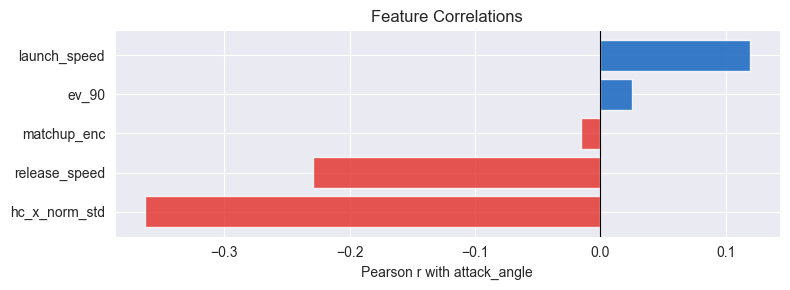

In [127]:
corr = df_model[ALL_FEATURES + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()

fig, ax = plt.subplots(figsize=(8, 0.4 * len(corr) + 1))
colors = ["#E53935" if v < 0 else "#1565C0" for v in corr.values]
ax.barh(corr.index, corr.values, color=colors, alpha=0.85)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Pearson r with attack_angle")
ax.set_title("Feature Correlations")
plt.tight_layout()
plt.show()


## 5. Train XGBoost

In [128]:
X_raw = df_model[ALL_FEATURES].copy()
y     = df_model[TARGET].values

scaler = StandardScaler()
X_raw[NUMERIC_FEATURES] = scaler.fit_transform(X_raw[NUMERIC_FEATURES])
X = X_raw.values

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.15, random_state=42)
print(f"Train: {len(X_train):,}   Val: {len(X_val):,}")


Train: 96,336   Val: 17,001


In [129]:
# ── Hyperparameters (edit here) ───────────────────────────────────────────────
model = XGBRegressor(
    n_estimators          = 800,
    learning_rate         = 0.04,
    max_depth             = 5,
    subsample             = 0.8,
    colsample_bytree      = 0.8,
    min_child_weight      = 20,
    reg_lambda            = 2.0,
    random_state          = 42,
    eval_metric           = "mae",
    early_stopping_rounds = 40,
    verbosity             = 0,
    device                = "cpu",
)

model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=False,
)

preds_val = model.predict(X_val)
mae = mean_absolute_error(y_val, preds_val)
r2  = r2_score(y_val, preds_val)

print(f"Validation MAE  : {mae:.2f}°")
print(f"Validation R²   : {r2:.4f}")
print(f"Best iteration  : {model.best_iteration}")


Validation MAE  : 5.54°
Validation R²   : 0.3202
Best iteration  : 798


## 6. Evaluate

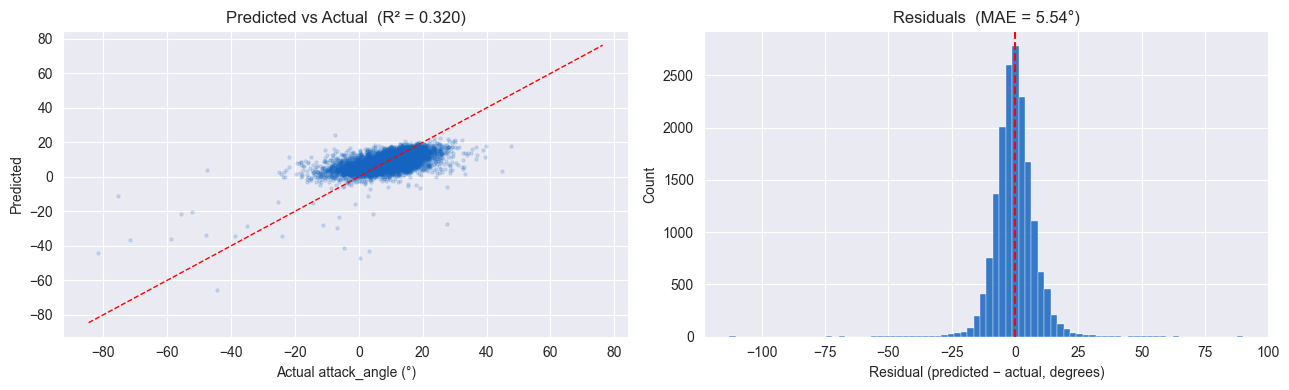

Residual std : 7.59°
Bias (mean)  : -0.085°


In [130]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sample_idx = np.random.choice(len(y_val), size=min(5000, len(y_val)), replace=False)
axes[0].scatter(y_val[sample_idx], preds_val[sample_idx], alpha=0.15, s=5, color="#1565C0")
lims = [min(y_val.min(), preds_val.min()), max(y_val.max(), preds_val.max())]
axes[0].plot(lims, lims, "r--", linewidth=1)
axes[0].set_xlabel("Actual attack_angle (°)")
axes[0].set_ylabel("Predicted")
axes[0].set_title(f"Predicted vs Actual  (R² = {r2:.3f})")

residuals = preds_val - y_val
axes[1].hist(residuals, bins=80, color="#1565C0", alpha=0.85, edgecolor="white", linewidth=0.3)
axes[1].axvline(0, color="red", linewidth=1.5, linestyle="--")
axes[1].set_xlabel("Residual (predicted − actual, degrees)")
axes[1].set_ylabel("Count")
axes[1].set_title(f"Residuals  (MAE = {mae:.2f}°)")

plt.tight_layout()
plt.show()
print(f"Residual std : {residuals.std():.2f}°")
print(f"Bias (mean)  : {residuals.mean():.3f}°")


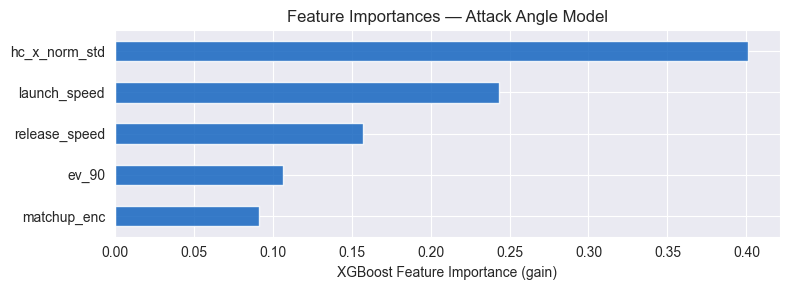

In [131]:
importances = pd.Series(model.feature_importances_, index=ALL_FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(8, 0.4 * len(importances) + 1))
importances.plot.barh(ax=ax, color="#1565C0", alpha=0.85)
ax.set_xlabel("XGBoost Feature Importance (gain)")
ax.set_title("Feature Importances — Attack Angle Model")
plt.tight_layout()
plt.show()


Qualified batters (≥25 BBE): 539
OLS slope : 0.3950
r²        : 0.5440
Spearman ρ: 0.7233
p-value   : 1.28e-93


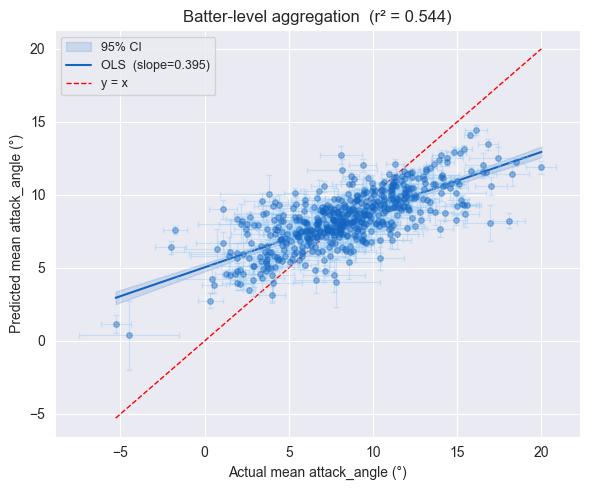

In [132]:
# ── Per-batter aggregation + OLS CI ──────────────────────────────────────────
df_model_pred = df_model.copy()
df_model_pred["pred"]   = model.predict(X_raw.values)
df_model_pred["batter"] = df.loc[df_model.index, "batter"].values

def batter_means(df_in, min_bbe=25):
    return (
        df_in.groupby("batter")["pred"]
        .agg(n="count", mean="mean")
        .query(f"n >= {min_bbe}")
    )

batter_agg = (
    df_model_pred
    .groupby("batter")
    .agg(
        n           = ("pred", "count"),
        mean_pred   = ("pred", "mean"),
        mean_actual = (TARGET, "mean"),
        se_pred     = ("pred", lambda x: x.std() / np.sqrt(len(x))),
        se_actual   = (TARGET, lambda x: x.std() / np.sqrt(len(x))),
    )
    .query("n >= 25")
    .sort_values("mean_actual")
    .reset_index()
)

x = batter_agg["mean_actual"].values
y_ols = batter_agg["mean_pred"].values
n = len(x)

slope, intercept, r, p_val, se_slope = stats.linregress(x, y_ols)
r2_batter = r**2
y_hat     = intercept + slope * x
mse       = ((y_ols - y_hat)**2).sum() / (n - 2)

x_range  = np.linspace(x.min(), x.max(), 200)
y_range  = intercept + slope * x_range
x_mean   = x.mean()
se_band  = np.sqrt(mse * (1/n + (x_range - x_mean)**2 / ((x - x_mean)**2).sum()))
t_crit   = stats.t.ppf(0.975, df=n - 2)
ci_upper = y_range + t_crit * se_band
ci_lower = y_range - t_crit * se_band

rho_batter, _ = spearmanr(batter_agg["mean_actual"], batter_agg["mean_pred"])
print(f"Qualified batters (≥25 BBE): {n}")
print(f"OLS slope : {slope:.4f}")
print(f"r²        : {r2_batter:.4f}")
print(f"Spearman ρ: {rho_batter:.4f}")
print(f"p-value   : {p_val:.2e}")

fig, ax = plt.subplots(figsize=(6, 5))
ax.fill_between(x_range, ci_lower, ci_upper, alpha=0.15, color="#1565C0", label="95% CI")
ax.plot(x_range, y_range, color="#1565C0", linewidth=1.5, label=f"OLS  (slope={slope:.3f})")
ax.plot([x.min(), x.max()], [x.min(), x.max()], "r--", linewidth=1, label="y = x")
ax.errorbar(x, y_ols,
            xerr=batter_agg["se_actual"], yerr=batter_agg["se_pred"],
            fmt="o", markersize=4, alpha=0.4,
            color="#1565C0", ecolor="#90CAF9", elinewidth=0.8, capsize=2)
ax.set_xlabel("Actual mean attack_angle (°)")
ax.set_ylabel("Predicted mean attack_angle (°)")
ax.set_title(f"Batter-level aggregation  (r² = {r2_batter:.3f})")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()


In [133]:
# ── Isotonic calibration ──────────────────────────────────────────────────────
iso = IsotonicRegression(out_of_bounds="clip")
iso.fit(batter_agg["mean_pred"], batter_agg["mean_actual"])
batter_agg["mean_pred_cal"] = iso.predict(batter_agg["mean_pred"])

slope_cal, _, r_cal, _, _ = stats.linregress(
    batter_agg["mean_actual"], batter_agg["mean_pred_cal"]
)
rho_cal, _ = spearmanr(batter_agg["mean_actual"], batter_agg["mean_pred_cal"])
print(f"Post-calibration slope      : {slope_cal:.4f}")
print(f"Post-calibration r²         : {r_cal**2:.4f}")
print(f"Post-calibration Spearman ρ : {rho_cal:.4f}")


Post-calibration slope      : 0.5734
Post-calibration r²         : 0.5734
Post-calibration Spearman ρ : 0.7368


## 7. Reliability & Stickiness

In [134]:
MIN_BBE  = 10
MAX_BBE  = 150
STEP     = 5
N_SPLITS = 200
N_ITEMS  = 5

df_rel    = df_model_pred.copy()
thresholds = range(MIN_BBE, MAX_BBE + STEP, STEP)
results   = []

for thresh in thresholds:
    eligible = (
        df_rel.groupby("batter")
        .filter(lambda x: len(x) >= thresh * N_ITEMS)
        ["batter"].unique()
    )
    if len(eligible) < 20:
        continue

    sub    = df_rel[df_rel["batter"].isin(eligible)]
    alphas = []

    for _ in range(N_SPLITS):
        items = (
            sub.groupby("batter")
            .apply(lambda x: x.sample(frac=1, random_state=None)
                              .assign(item=lambda d: np.arange(len(d)) % N_ITEMS))
            .reset_index(drop=True)
            .groupby(["batter", "item"])["pred"]
            .mean()
            .unstack("item")
            .dropna()
        )
        k         = items.shape[1]
        item_var  = items.var(axis=0, ddof=1).sum()
        total_var = items.sum(axis=1).var(ddof=1)
        alphas.append((k / (k - 1)) * (1 - item_var / total_var))

    results.append({
        "thresh":     thresh,
        "n_batters":  len(eligible),
        "alpha_mean": np.mean(alphas),
        "alpha_std":  np.std(alphas),
    })

rel = pd.DataFrame(results)


In [135]:
# ── Pull 2025 for stickiness ──────────────────────────────────────────────────
CACHE_2025 = Path("statcast_2025.parquet")

if CACHE_2025.exists():
    print("Loading 2025 from cache …")
    raw_2025 = pd.read_parquet(CACHE_2025)
else:
    print("Pulling 2025 from Baseball Savant …")
    chunks = []
    for start, end in [
        ("2025-03-20", "2025-04-30"), ("2025-05-01", "2025-05-31"),
        ("2025-06-01", "2025-06-30"), ("2025-07-01", "2025-07-31"),
        ("2025-08-01", "2025-08-31"), ("2025-09-01", "2025-09-28"),
    ]:
        print(f"  {start} → {end}")
        chunks.append(statcast(start, end, verbose=False))
    raw_2025 = pd.concat(chunks, ignore_index=True)
    raw_2025.to_parquet(CACHE_2025)
    print(f"Cached to {CACHE_2025}")

swing_mask_2025 = (
    raw_2025[TARGET].notna() &
    raw_2025["bat_speed"].notna() &
    raw_2025["swing_length"].notna() &
    raw_2025["launch_speed"].notna() &
    raw_2025["hc_x"].notna() &
    raw_2025["stand"].notna() &
    raw_2025["pitch_type"].notna()
)
df_2025 = engineer_features(raw_2025[swing_mask_2025].copy()).reset_index(drop=True)

# ── ev_90: compute from 2025 data, keyed on batter_id ────────────────────────
df_2025["batter"] = raw_2025.loc[raw_2025[swing_mask_2025].index, "batter"].values

ev_90_2025 = (
    df_2025.groupby("batter")["launch_speed"]
    .quantile(0.90)
    .rename("ev_90")
)
df_2025 = df_2025.merge(ev_90_2025, on="batter", how="left")

# ── Apply 2024 standardization constants ─────────────────────────────────────
for side in ["R", "L"]:
    mask = df_2025["stand"] == side
    df_2025.loc[mask, "hc_x_norm_std"] = (
        (df_2025.loc[mask, "hc_x_norm"] - HC_X_NORM_MU[side]) / HC_X_NORM_SIG[side]
    )

# ── Recompute depth interactions using saved bin edges ────────────────────────
depth_raw = df_2025["intercept_ball_minus_batter_pos_y_inches"].fillna(
    df_swings["intercept_ball_minus_batter_pos_y_inches"].median()
)
df_2025["contact_depth_bin"] = pd.cut(
    depth_raw, bins=DEPTH_BINS, labels=[0, 1], right=True
).astype(float)
df_2025["depth_x_spray"]    = df_2025["contact_depth_bin"] * df_2025["hc_x_norm_std"]
df_2025["depth_x_location"] = df_2025["contact_depth_bin"] * df_2025["plate_x_rel"]

# ── VAA ───────────────────────────────────────────────────────────────────────
t_plate_2025   = (
    (-df_2025["vy0"] - np.sqrt(df_2025["vy0"]**2 - 4 * (0.5 * df_2025["ay"]) * (Y0 - Y_PLATE)))
    / (2 * 0.5 * df_2025["ay"])
)
df_2025["vaa"] = np.degrees(np.arctan(
    (df_2025["vz0"] + df_2025["az"] * t_plate_2025) /
    (df_2025["vy0"] + df_2025["ay"] * t_plate_2025).abs()
))

# ── Predict ───────────────────────────────────────────────────────────────────
df_2025_model = df_2025[ALL_FEATURES + [TARGET]].dropna().reset_index(drop=True)
X_2025 = df_2025_model[ALL_FEATURES].copy()
X_2025[NUMERIC_FEATURES] = scaler.transform(X_2025[NUMERIC_FEATURES])
df_2025_model["pred"]   = model.predict(X_2025.values)
df_2025_model["batter"] = df_2025.loc[df_2025_model.index, "batter"].values

print(f"2025 model rows: {len(df_2025_model):,}")


Loading 2025 from cache …
2025 model rows: 118,524


   min_bbe    n_paired       rho
        25         431    0.2263
        50         377    0.2555
        75         338    0.2663
       100         297    0.2366


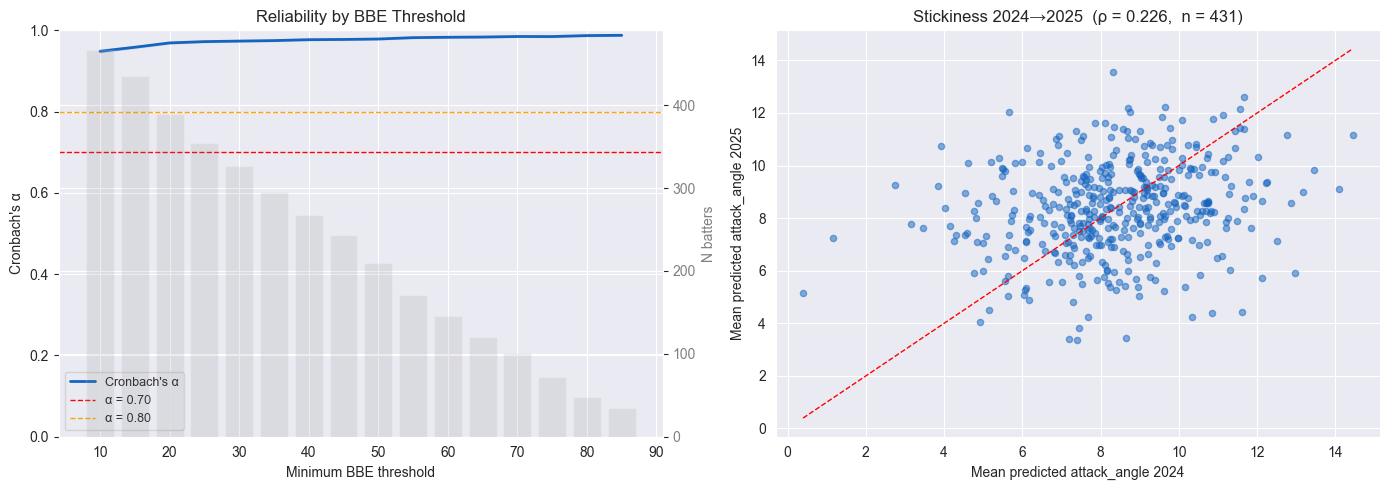

In [136]:
# ── Stickiness across BBE thresholds ─────────────────────────────────────────
print(f"{'min_bbe':>10}  {'n_paired':>10}  {'rho':>8}")
for min_bbe in [25, 50, 75, 100]:
    agg_24 = batter_means(df_model_pred, min_bbe).rename(columns={"mean": "y2024", "n": "n_2024"})
    agg_25 = batter_means(df_2025_model, min_bbe).rename(columns={"mean": "y2025", "n": "n_2025"})
    paired = agg_24.join(agg_25, how="inner")
    if len(paired) >= 20:
        rho, _ = spearmanr(paired["y2024"], paired["y2025"])
        print(f"{min_bbe:>10}  {len(paired):>10}  {rho:>8.4f}")

# Use 25 BBE for the plot
agg_24 = batter_means(df_model_pred, 25).rename(columns={"mean": "y2024", "n": "n_2024"})
agg_25 = batter_means(df_2025_model, 25).rename(columns={"mean": "y2025", "n": "n_2025"})
paired = agg_24.join(agg_25, how="inner")
rho_stick, p_stick = spearmanr(paired["y2024"], paired["y2025"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax1 = axes[0]
ax2 = ax1.twinx()
ax1.plot(rel["thresh"], rel["alpha_mean"], color="#1565C0", linewidth=2, label="Cronbach's α")
ax1.fill_between(rel["thresh"],
                 rel["alpha_mean"] - rel["alpha_std"],
                 rel["alpha_mean"] + rel["alpha_std"],
                 alpha=0.15, color="#1565C0")
ax1.axhline(0.70, color="red",    linewidth=1, linestyle="--", label="α = 0.70")
ax1.axhline(0.80, color="orange", linewidth=1, linestyle="--", label="α = 0.80")
ax1.set_xlabel("Minimum BBE threshold")
ax1.set_ylabel("Cronbach's α")
ax1.set_title("Reliability by BBE Threshold")
ax1.legend(fontsize=9)
ax1.set_ylim(0, 1)
ax2.bar(rel["thresh"], rel["n_batters"], alpha=0.15, color="gray", width=STEP * 0.8)
ax2.set_ylabel("N batters", color="gray")
ax2.tick_params(axis="y", labelcolor="gray")

axes[1].scatter(paired["y2024"], paired["y2025"], alpha=0.5, s=20, color="#1565C0")
lims = [paired[["y2024","y2025"]].min().min(), paired[["y2024","y2025"]].max().max()]
axes[1].plot(lims, lims, "r--", linewidth=1)
axes[1].set_xlabel("Mean predicted attack_angle 2024")
axes[1].set_ylabel("Mean predicted attack_angle 2025")
axes[1].set_title(f"Stickiness 2024→2025  (ρ = {rho_stick:.3f},  n = {len(paired)})")

plt.tight_layout()
plt.show()


In [124]:
agg_24_raw = batter_means(df_model_pred, 25).rename(columns={"mean": "y2024", "n": "n_2024"})
agg_25_raw = batter_means(df_2025_model, 25).rename(columns={"mean": "y2025", "n": "n_2025"})
paired_raw = agg_24_raw.join(agg_25_raw, how="inner")
rho_raw, _ = spearmanr(paired_raw["y2024"], paired_raw["y2025"])
print(f"Raw prediction stickiness: ρ = {rho_raw:.4f}  n = {len(paired_raw)}")

Raw prediction stickiness: ρ = 0.3069  n = 431


In [119]:
raw_24 = (df.groupby("batter")[TARGET]
           .agg(n="count", mean="mean").query("n >= 25"))
raw_25 = (df_2025.groupby("batter")[TARGET]
           .agg(n="count", mean="mean").query("n >= 25"))
paired_raw = raw_24["mean"].rename("y2024").to_frame().join(
    raw_25["mean"].rename("y2025"), how="inner")
rho_raw, _ = spearmanr(paired_raw["y2024"], paired_raw["y2025"])
print(f"Raw attack_angle stickiness: ρ = {rho_raw:.4f}  n = {len(paired_raw)}")

Raw attack_angle stickiness: ρ = 0.8213  n = 431


## 8. Save Artifacts

In [ ]:
model.save_model(str(MODEL_DIR / "attack_angle_model.json"))
joblib.dump(scaler, MODEL_DIR / "attack_angle_scaler.pkl")
joblib.dump(iso,    MODEL_DIR / "attack_angle_isotonic.pkl")

meta = {
    "all_features":        ALL_FEATURES,
    "numeric_features":    NUMERIC_FEATURES,
    "pitch_type_map":      PITCH_TYPE_MAP,
    "stand_map":           STAND_MAP,
    "p_throws_map":        P_THROWS_MAP,
    "target":              TARGET,
    "val_mae":             float(mae),
    "val_r2":              float(r2),
    "n_train":             len(X_train),
    "n_val":               len(X_val),
    "mlb_mean":            float(y.mean()),
    "mlb_std":             float(y.std()),
    "contact_depth_bins":  DEPTH_BINS,
    "hc_x_norm_mu":        HC_X_NORM_MU,
    "hc_x_norm_sig":       HC_X_NORM_SIG,
    "feature_importances": dict(
        sorted(zip(ALL_FEATURES, model.feature_importances_),
               key=lambda x: x[1], reverse=True)
    ),
}
joblib.dump(meta, MODEL_DIR / "attack_angle_meta.pkl")

print("Saved:")
print("  models/attack_angle_model.json")
print("  models/attack_angle_scaler.pkl")
print("  models/attack_angle_isotonic.pkl")
print("  models/attack_angle_meta.pkl")
print(f"\nMLB population stats:")
print(f"  mean attack_angle : {meta['mlb_mean']:.2f}°")
print(f"  std  attack_angle : {meta['mlb_std']:.2f}°")
